# Worker Safety Vest Color Identifier

This notebook follows the image-processing breakdown from `activity02.ipynb`. It detects the bright yellow-green safety vests in `Assets/workers.jpg` using HSV color segmentation, morphology, connected components, and contour annotation.

## 1. Import image-processing libraries

NumPy stores image arrays, OpenCV performs color conversion and segmentation, Matplotlib displays each processing stage, and scikit-image measures connected regions.

In [21]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage.measure import label, regionprops

## 2. Load and display the worker image

OpenCV reads images in BGR order. The image is converted to RGB before displaying it in the notebook.

Image width: 1536px
Image height: 2048px
Color channels: 3


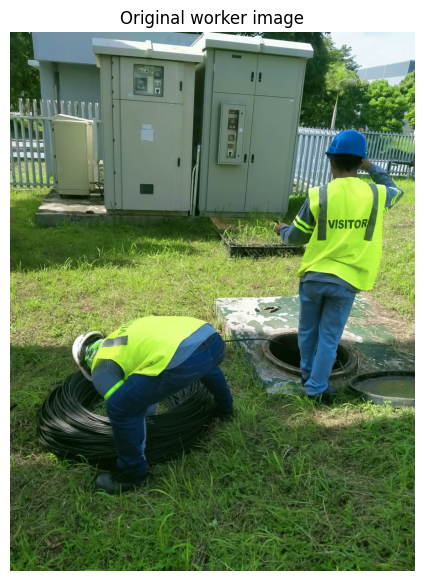

In [22]:
IMAGE_PATH = Path('Assets/workers.jpg')
image_bgr = cv2.imread(str(IMAGE_PATH))
if image_bgr is None:
    raise FileNotFoundError(f'Could not load image: {IMAGE_PATH}')

image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
height, width = image_rgb.shape[:2]
print(f'Image width: {width}px')
print(f'Image height: {height}px')
print(f'Color channels: {image_rgb.shape[2]}')

plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
plt.title('Original worker image')
plt.axis('off')
plt.show()

## 3. Break the image into RGB channels

Viewing the channels separately helps show why the vest is detectable. The vest is bright in all channels, while HSV will later make its yellow-green hue explicit.

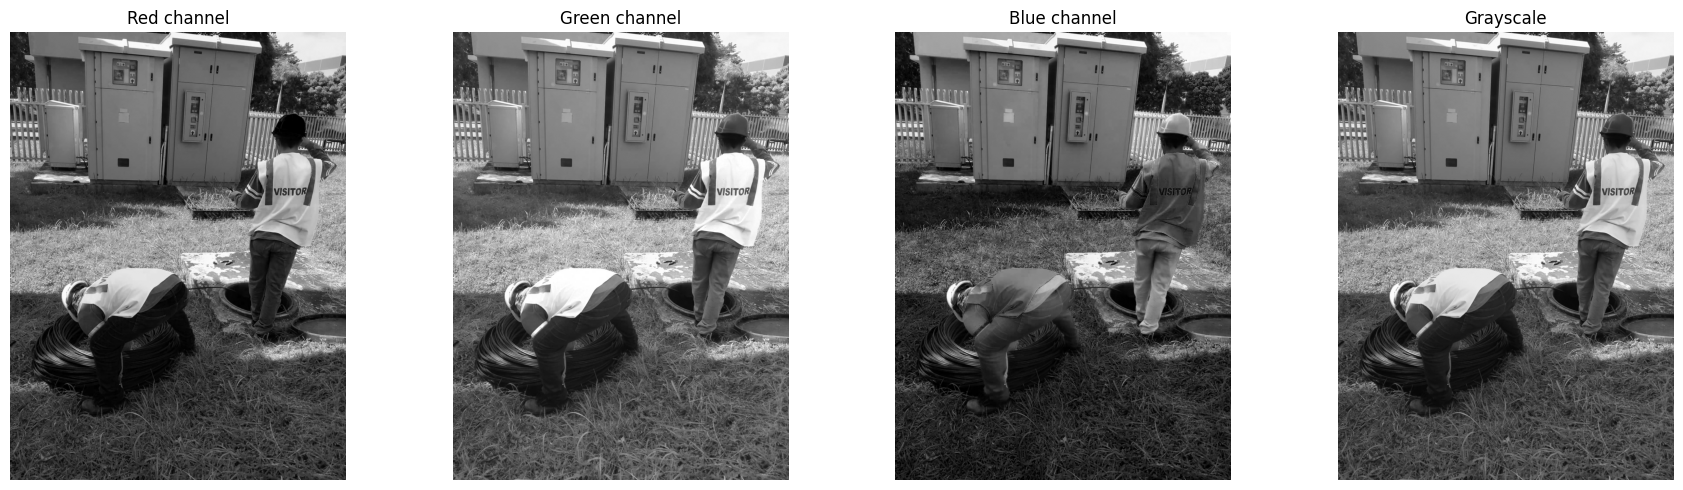

In [30]:
red, green, blue = cv2.split(image_rgb)
gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for axis, channel, title in zip(
    axes, [red, green, blue, gray],
    ['Red channel', 'Green channel', 'Blue channel', 'Grayscale'],
):
    axis.imshow(channel, cmap='gray')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

## 4. Convert RGB to HSV

HSV separates hue from brightness and saturation. OpenCV stores hue from 0 to 179, so a yellow-green vest is selected with a hue range near 25 to 45.

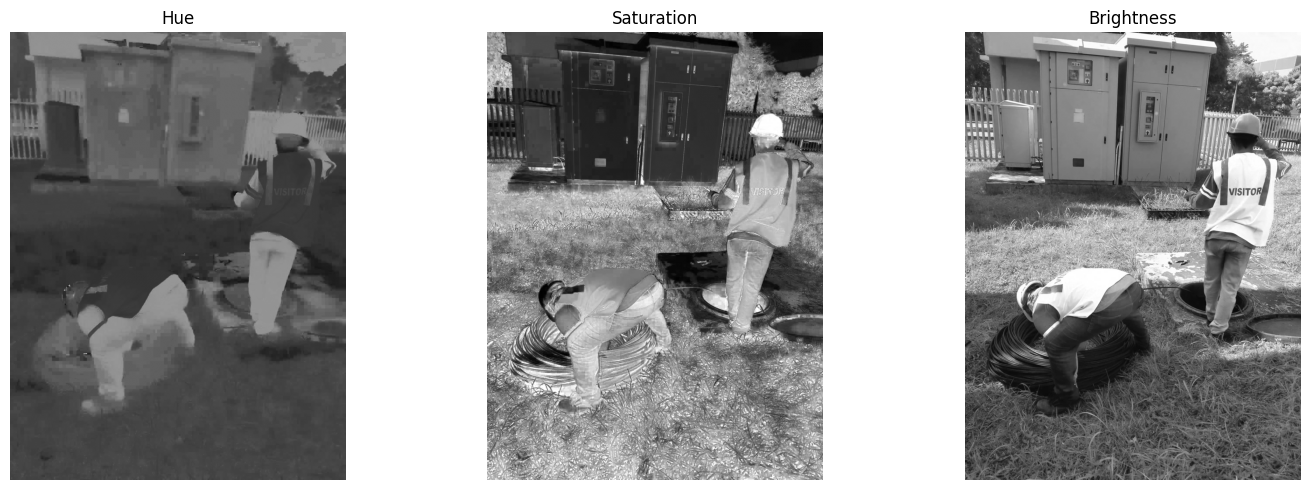

In [31]:
hsv = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2HSV)
hue, saturation, value = cv2.split(hsv)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for axis, channel, title in zip(
    axes, [hue, saturation, value], ['Hue', 'Saturation', 'Brightness'],
):
    axis.imshow(channel, cmap='gray')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

## 5. Create a vest-color mask

The mask keeps pixels that are yellow-green, strongly saturated, and bright. Adjust these HSV limits if lighting or vest color changes.

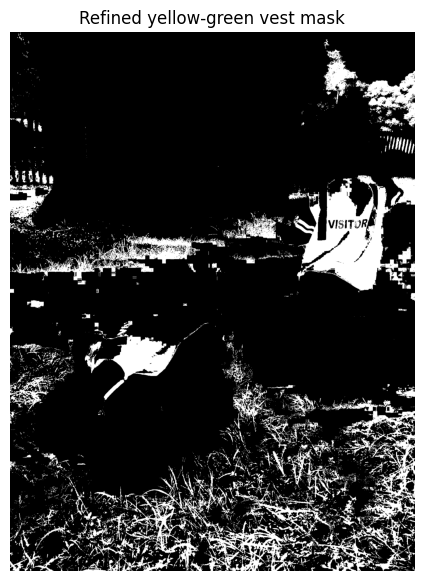

In [37]:
# Fluorescent vest fabric is greener than the surrounding grass in this image.
LOWER_VEST_HSV = np.array([39, 90, 100], dtype=np.uint8)
UPPER_VEST_HSV = np.array([55, 255, 255], dtype=np.uint8)
vest_mask = cv2.inRange(hsv, LOWER_VEST_HSV, UPPER_VEST_HSV)

plt.figure(figsize=(12, 7))
plt.imshow(vest_mask, cmap='gray')
plt.title('Refined yellow-green vest mask')
plt.axis('off')
plt.show()

## 6. Clean the mask with morphology

Opening removes small color specks and closing fills small holes in the vest regions.

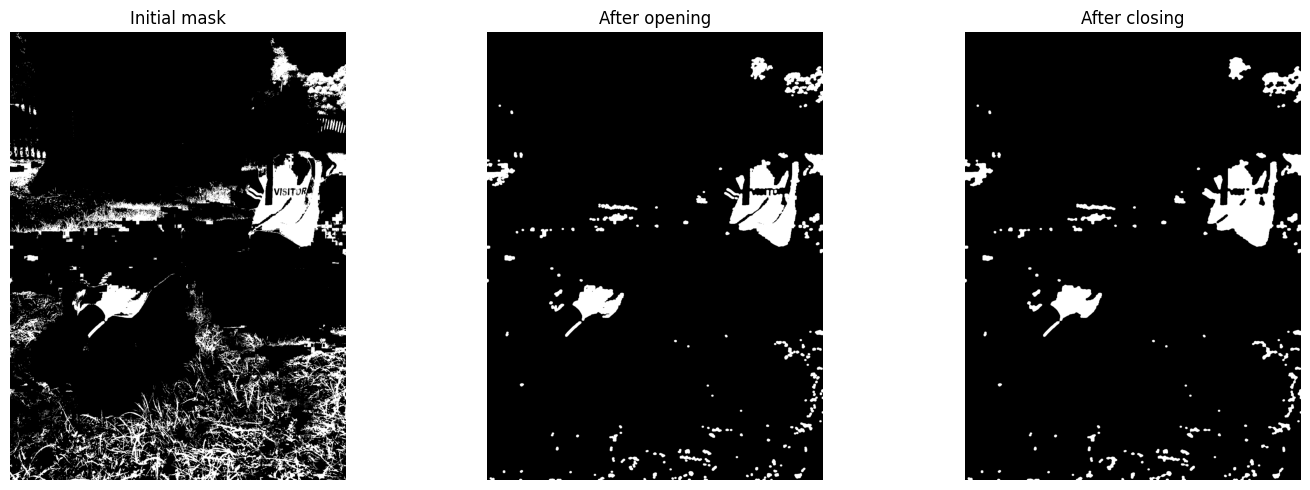

In [38]:
morphology_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
opened_mask = cv2.morphologyEx(vest_mask, cv2.MORPH_OPEN, morphology_kernel)
clean_vest_mask = cv2.morphologyEx(opened_mask, cv2.MORPH_CLOSE, morphology_kernel)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for axis, mask, title in zip(
    axes, [vest_mask, opened_mask, clean_vest_mask],
    ['Initial mask', 'After opening', 'After closing'],
):
    axis.imshow(mask, cmap='gray')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

## 7. Find connected vest regions

Each connected component is a candidate vest area. Small components are ignored as noise, and the remaining regions are measured by area and bounding box.

In [39]:
MIN_VEST_AREA = 10000
MAX_VEST_AREA = 100000

# Keep the central worker area and reject grass along the image edges.
roi_x_min, roi_x_max = int(width * 0.15), int(width * 0.95)
roi_y_min, roi_y_max = int(height * 0.25), int(height * 0.80)

vest_labels = label(clean_vest_mask > 0, connectivity=2)
vest_regions = []

for region in regionprops(vest_labels):
    center_y, center_x = region.centroid
    inside_worker_roi = (
        roi_x_min <= center_x <= roi_x_max
        and roi_y_min <= center_y <= roi_y_max
    )
    if MIN_VEST_AREA <= region.area <= MAX_VEST_AREA and inside_worker_roi:
        vest_regions.append(region)

print(f'Detected vest regions: {len(vest_regions)}')
print(f'Worker ROI: x={roi_x_min}:{roi_x_max}, y={roi_y_min}:{roi_y_max}')
for index, region in enumerate(vest_regions, start=1):
    print(f'Vest {index}: area={region.area:.0f} pixels, bbox={region.bbox}')

Detected vest regions: 2
Worker ROI: x=230:1459, y=512:1638
Vest 1: area=71210 pixels, bbox=(583, 1084, 982, 1430)
Vest 2: area=24078 pixels, bbox=(1155, 357, 1394, 626)


## 8. Annotate the detected vests

Green contours and labels are drawn on the original image so the detected worker vests can be checked against the source scene.

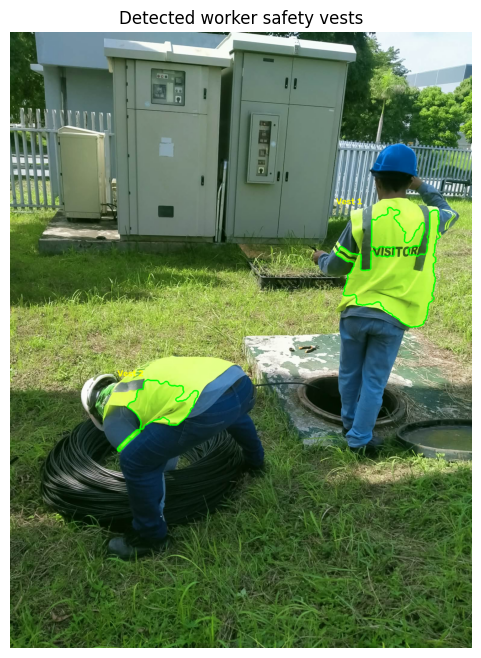

In [40]:
annotated_image = image_rgb.copy()
for index, region in enumerate(vest_regions, start=1):
    min_row, min_col, max_row, max_col = region.bbox
    contours, _ = cv2.findContours(
        (vest_labels == region.label).astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE,
    )
    cv2.drawContours(annotated_image, contours, -1, (0, 255, 0), 4)

    label_text = f'Vest {index}'
    label_y = max(min_row - 10, 25)
    cv2.putText(
        annotated_image, label_text, (min_col, label_y),
        cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 0), 3, cv2.LINE_AA
    )

plt.figure(figsize=(14, 8))
plt.imshow(annotated_image)
plt.title('Detected worker safety vests')
plt.axis('off')
plt.show()

## 9. Detection summary

The final count reports how many separated vest regions were found by the color-processing pipeline.

In [41]:
print(f'Total detected vest regions: {len(vest_regions)}')
print(f'Total vest pixels: {int(sum(region.area for region in vest_regions))}')

Total detected vest regions: 2
Total vest pixels: 95288
